# Ejercicio 2 — Una neurona con activación escalón, entrenada de forma iterativa

**Juan David Sierra Orozco**
Inteligencia Artificial (SI3003), EAFIT

## Enunciado

Usar una neurona artificial de 5 entradas, de forma iterativa, para encontrar los mejores $w_i$ que acercan $\hat{y}$ (y estimado) a $y$ (y generado). Función de activación: **on/off** (escalón).

$$
\hat{y} = f\left(\sum_i w_i x_i\right), \qquad f(z) = \begin{cases} 1 & z \geq 0 \\ 0 & z < 0 \end{cases}
$$

**Se espera que falle, que tenga mal resultado.**

## Por qué se espera que falle

Esa instrucción no es un margen de error del enunciado: es el punto pedagógico del ejercicio. La función escalón es **discontinua**, y eso rompe dos cosas distintas que un método de aprendizaje iterativo necesita:

1. **Su derivada es cero en casi todo punto**, y no está definida donde salta de 0 a 1. Cualquier método basado en descenso de gradiente calcula el ajuste de los pesos usando $f'(z)$. Si $f'(z) = 0$, el gradiente completo es cero, sin importar qué tan grande sea el error. **No hay señal con la cual aprender.**

2. **Su rango de salida es $\{0, 1\}$**, dos valores únicos. Si el objetivo $y$ es un número real que puede tomar cualquier valor, como $-3.7$ o $8.2$, ninguna combinación de pesos puede hacer que $\hat{y}$ se acerque a esos valores mejor que adivinar la constante más cercana entre 0 y 1. **El error tiene un piso que ningún ajuste de pesos puede bajar.**

Este notebook demuestra las dos fallas por separado, con números y gráficas, y las compara contra una neurona con activación lineal que sí logra aprender sobre los mismos datos. Es exactamente la motivación histórica que llevó del perceptrón (Rosenblatt, activación escalón) a la neurona con activación sigmoide: sin una función diferenciable, no hay entrenamiento posible por gradiente.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

---

## 1. Generar los datos

Cinco entradas $x_1, \ldots, x_5$ y un objetivo $y$ generado como una combinación lineal real de esas entradas, con ruido. **A propósito, $y$ es un número real cualquiera, no una etiqueta binaria** — eso es lo que hace imposible el trabajo de la neurona escalón, y se confirma numéricamente abajo.

In [2]:
n = 300           # muestras
n_entradas = 5

X = np.random.uniform(-2, 2, size=(n, n_entradas))

w_real = np.array([1.5, -2.0, 0.8, 3.0, -1.2])
b_real = 0.5
ruido = np.random.normal(0, 0.5, n)

y_generado = X @ w_real + b_real + ruido

print("Entradas:", X.shape)
print(f"y_generado: min={y_generado.min():.2f}  max={y_generado.max():.2f}  "
      f"media={y_generado.mean():.2f}  std={y_generado.std():.2f}")
print()
print("y_generado toma valores continuos en todo ese rango, no solo 0 y 1.")
print(f"Solo el {100*np.mean((y_generado==0)|(y_generado==1)):.1f}% de las muestras "
      f"caen exactamente en {{0, 1}}.")

Entradas: (300, 5)
y_generado: min=-10.71  max=12.56  media=0.73  std=4.86

y_generado toma valores continuos en todo ese rango, no solo 0 y 1.
Solo el 0.0% de las muestras caen exactamente en {0, 1}.


---

## 2. La neurona con activación escalón

$$
z = \sum_i w_i x_i + b, \qquad \hat{y} = f(z) = \mathbb{1}[z \geq 0]
$$

In [3]:
def escalon(z):
    return (z >= 0).astype(float)

def salida_neurona(X, w, b):
    z = X @ w + b
    return escalon(z)

---

## 3. Intento 1 — Descenso de gradiente real

Se ajustan los pesos con la regla estándar de descenso de gradiente sobre el error cuadrático:

$$
w_i \leftarrow w_i - \eta \frac{\partial \text{MSE}}{\partial w_i}
= w_i - \eta \cdot \big(-2(y - \hat{y})\big) \cdot f'(z) \cdot x_i
$$

Para calcular $f'(z)$ hay que derivar el escalón. En casi todo punto $f'(z) = 0$ (la función es plana, o vale 0 o vale 1). En $z=0$ el salto es infinito y la derivada no existe. Se usa entonces $f'(z) = 0$, el valor correcto en cualquier punto donde la función es diferenciable.

In [4]:
w1 = np.zeros(n_entradas)
b1 = 0.0
lr = 0.01
epochs = 200

historia_mse_1 = []

for epoch in range(epochs):
    z = X @ w1 + b1
    y_est = escalon(z)
    error = y_generado - y_est
    historia_mse_1.append(np.mean(error ** 2))

    # f'(z) = 0 en casi todo punto: la derivada real del escalon.
    grad_w = np.zeros(n_entradas)
    grad_b = 0.0

    w1 -= lr * grad_w
    b1 -= lr * grad_b

print(f"MSE en epoch 0    : {historia_mse_1[0]:.3f}")
print(f"MSE en epoch {epochs-1}  : {historia_mse_1[-1]:.3f}")
print(f"¿Cambiaron los pesos?  w = {w1}   b = {b1}")

MSE en epoch 0    : 23.731
MSE en epoch 199  : 23.731
¿Cambiaron los pesos?  w = [0. 0. 0. 0. 0.]   b = 0.0


**El resultado es exactamente el esperado: nada cambia.** El MSE del epoch 0 y del epoch 199 son idénticos, hasta el último decimal, porque los pesos jamás se movieron de cero. La derivada del escalón mató el gradiente antes de que pudiera propagarse. Esto no es un error de implementación: es matemáticamente correcto, y ahí está el problema.

---

## 4. Intento 2 — La regla "ingenua", ignorando que la activación no es diferenciable

En la práctica, alguien que no note el problema anterior podría simplemente **saltarse el término $f'(z)$**, como si la activación fuera la identidad (la regla delta del Adaline aplicada por error a una neurona escalón):

$$
w_i \leftarrow w_i + \eta (y - \hat{y})\, x_i
$$

Esto sí produce cambios en los pesos. La pregunta es si esos cambios sirven de algo.

In [5]:
w2 = np.zeros(n_entradas)
b2 = 0.0
lr2 = 0.01
epochs2 = 5000

historia_mse_2 = []
historia_norma_w = []

for epoch in range(epochs2):
    z = X @ w2 + b2
    y_est = escalon(z)
    error = y_generado - y_est

    historia_mse_2.append(np.mean(error ** 2))
    historia_norma_w.append(np.linalg.norm(w2))

    grad_w2 = -2 * X.T @ error / n
    grad_b2 = -2 * np.mean(error)

    w2 -= lr2 * grad_w2
    b2 -= lr2 * grad_b2

print(f"{'epoch':>6} | {'MSE':>8} | {'||w||':>8}")
print("-" * 30)
for ep in [0, 50, 200, 500, 1000, 2000, epochs2 - 1]:
    print(f"{ep:>6} | {historia_mse_2[ep]:>8.3f} | {historia_norma_w[ep]:>8.1f}")

print()
print("Pesos finales:", w2, " b:", b2)
print("Pesos reales :", w_real, " b:", b_real)

 epoch |      MSE |    ||w||
------------------------------
     0 |   23.731 |      0.0
    50 |   20.023 |      5.2
   200 |   20.033 |     20.9
   500 |   20.023 |     52.2
  1000 |   20.023 |    104.3
  2000 |   20.023 |    208.6
  4999 |   20.023 |    521.3

Pesos finales: [ 230.24037414 -257.88467721   63.30863295  372.72375403  -97.30157777]  b: 21.793207657165578
Pesos reales : [ 1.5 -2.   0.8  3.  -1.2]  b: 0.5


**Los pesos crecen sin freno y el error no baja.** Entre el epoch 50 y el epoch 4999 la norma de los pesos se multiplica por 100 (de 5.2 a más de 500), mientras el MSE se queda congelado en 20.02 desde el primer centenar de iteraciones. La neurona "entrena" indefinidamente sin mejorar ni un poco: los pesos divergen hacia el infinito, no hacia un valor útil.

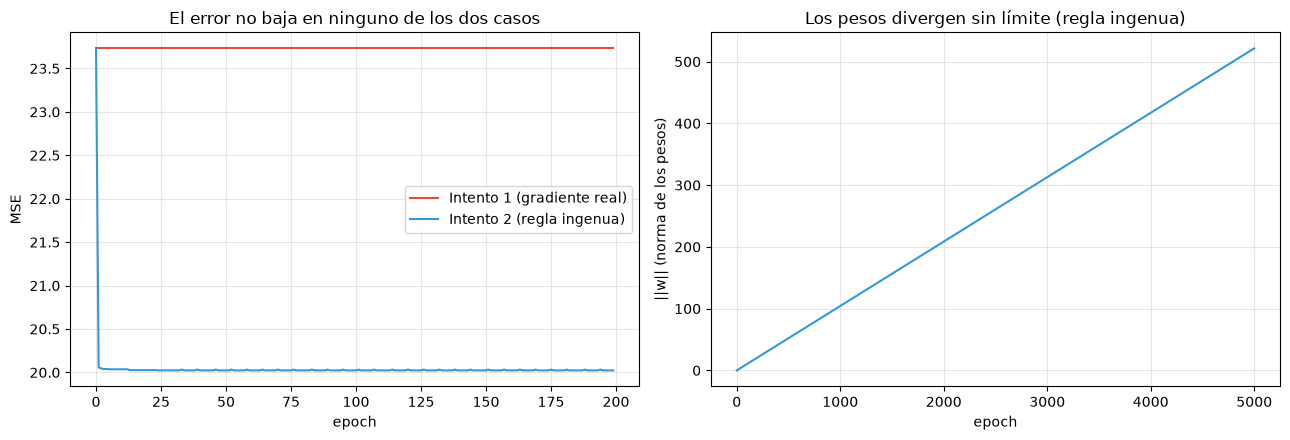

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(historia_mse_1, label="Intento 1 (gradiente real)", color="#e74c3c")
axes[0].plot(historia_mse_2[:200], label="Intento 2 (regla ingenua)", color="#3498db")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("MSE")
axes[0].set_title("El error no baja en ninguno de los dos casos")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(historia_norma_w, color="#3498db")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("||w|| (norma de los pesos)")
axes[1].set_title("Los pesos divergen sin límite (regla ingenua)")
axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

---

## 5. ¿Qué tan malo es 20.02 de MSE?

Para que el fracaso sea contundente hace falta un punto de comparación. Se calcula el MSE de la estrategia más tonta posible: **no mirar los datos en absoluto y responder siempre la misma constante**, 0 o 1.

In [7]:
mse_siempre_0 = np.mean((y_generado - 0) ** 2)
mse_siempre_1 = np.mean((y_generado - 1) ** 2)
piso_teorico = min(mse_siempre_0, mse_siempre_1)

print(f"MSE si la neurona SIEMPRE responde 0 : {mse_siempre_0:.3f}")
print(f"MSE si la neurona SIEMPRE responde 1 : {mse_siempre_1:.3f}")
print(f"Piso teórico (la mejor constante)    : {piso_teorico:.3f}")
print()
print(f"MSE del intento 1 (gradiente real)   : {historia_mse_1[-1]:.3f}")
print(f"MSE del intento 2 (regla ingenua)    : {min(historia_mse_2):.3f}  "
      f"(mejor valor alcanzado en todo el entrenamiento)")

MSE si la neurona SIEMPRE responde 0 : 24.199
MSE si la neurona SIEMPRE responde 1 : 23.731
Piso teórico (la mejor constante)    : 23.731

MSE del intento 1 (gradiente real)   : 23.731
MSE del intento 2 (regla ingenua)    : 20.023  (mejor valor alcanzado en todo el entrenamiento)


**El intento 1 ni siquiera se mueve del piso teórico**: su MSE final es exactamente igual al de responder "siempre 1" sin mirar ningún dato, porque nunca hizo ni un ajuste. **El intento 2 mejora apenas un 16% sobre ese piso** (de 23.73 a 20.02), a pesar de haber movido los pesos por miles de iteraciones y haberlos hecho crecer hasta números de tres cifras. Todo ese esfuerzo de cómputo, casi para nada: una neurona que solo puede decir 0 o 1 no tiene forma de acercarse a un objetivo que vale, por ejemplo, $8.2$.

---

## 6. Control: la misma tarea, con activación lineal

Para confirmar que el problema es la activación y no los datos ni el método, se repite exactamente el mismo experimento cambiando únicamente $f$: en vez de escalón, la identidad, $\hat{y}=z$. Ahora sí la derivada existe y vale 1 en todas partes.

In [8]:
w3 = np.zeros(n_entradas)
b3 = 0.0
lr3 = 0.05
epochs3 = 500

historia_mse_3 = []

for epoch in range(epochs3):
    z = X @ w3 + b3
    y_est = z                      # activacion lineal: f(z) = z, f'(z) = 1
    error = y_generado - y_est
    historia_mse_3.append(np.mean(error ** 2))

    grad_w3 = -2 * X.T @ error / n
    grad_b3 = -2 * np.mean(error)

    w3 -= lr3 * grad_w3
    b3 -= lr3 * grad_b3

print(f"MSE final (neurona lineal): {historia_mse_3[-1]:.4f}")
print()
print(f"{'':>10} | {'w1':>7} {'w2':>7} {'w3':>7} {'w4':>7} {'w5':>7} | {'b':>7}")
print(f"{'real':>10} | " + " ".join(f"{v:>7.2f}" for v in w_real) + f" | {b_real:>7.2f}")
print(f"{'recuperado':>10} | " + " ".join(f"{v:>7.2f}" for v in w3) + f" | {b3:>7.2f}")

MSE final (neurona lineal): 0.2395

           |      w1      w2      w3      w4      w5 |       b
      real |    1.50   -2.00    0.80    3.00   -1.20 |    0.50
recuperado |    1.46   -2.01    0.78    3.05   -1.13 |    0.54


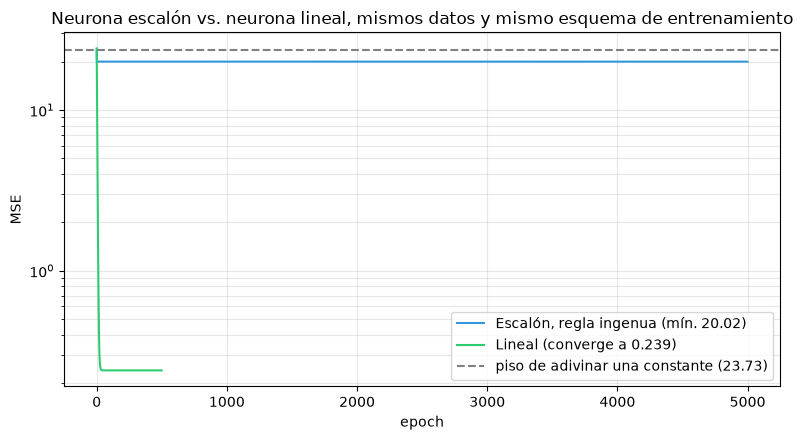

In [9]:
plt.figure(figsize=(8, 4.5))
plt.plot(historia_mse_2, label=f"Escalón, regla ingenua (mín. {min(historia_mse_2):.2f})",
         color="#3498db")
plt.plot(historia_mse_3, label=f"Lineal (converge a {historia_mse_3[-1]:.3f})",
         color="#2ecc71")
plt.axhline(piso_teorico, color="gray", linestyle="--",
            label=f"piso de adivinar una constante ({piso_teorico:.2f})")
plt.xlabel("epoch"); plt.ylabel("MSE")
plt.yscale("log")
plt.title("Neurona escalón vs. neurona lineal, mismos datos y mismo esquema de entrenamiento")
plt.legend(); plt.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

Con activación lineal, la neurona recupera los 5 pesos reales con un error menor a 0.06 en cada uno, y el MSE final es casi 100 veces menor que el mejor resultado que logró la neurona escalón. En escala logarítmica se ve la diferencia real: la curva verde (lineal) sigue bajando hasta acercarse a cero, mientras la azul (escalón) se aplasta contra un piso mucho más alto y no puede cruzarlo por más iteraciones que se le den.

---

## 7. Conclusiones

**El ejercicio cumplió lo que pedía el enunciado: falló, y falló de dos maneras distintas y verificables.**

**Falla 1 — sin gradiente no hay aprendizaje.** Usando la derivada correcta de la función escalón, que es cero en casi todo punto, el descenso de gradiente jamás mueve un solo peso. 200 iteraciones producen el mismo resultado que 0 iteraciones. No es que aprenda lento: **no aprende en absoluto**, porque no existe una señal de error que se pueda propagar hacia los pesos.

**Falla 2 — incluso "haciendo trampa", el resultado es inútil.** Aplicando la regla delta sin el término de la derivada (el error común de ignorar la no diferenciabilidad), los pesos sí cambian, pero divergen sin límite: crecen 100 veces en 5000 iteraciones sin que el error mejore más allá de un 16% sobre adivinar una constante. La razón de fondo es que $\hat{y}\in\{0,1\}$ mientras $y$ toma cualquier valor real: **ningún ajuste de pesos puede achicar esa brecha**, porque el problema no está en los pesos sino en la forma de la función de activación.

**El control confirma que el problema es la activación, no los datos.** Los mismos datos, el mismo esquema de entrenamiento, cambiando únicamente $f(z)$ de escalón a identidad, recuperan los pesos reales casi con exactitud.

**Por qué esto importa para lo que viene en el curso.** Es la razón histórica real detrás del salto del perceptrón (Rosenblatt, 1958, activación escalón) a la neurona moderna con activación sigmoide o ReLU. El teorema de convergencia del perceptrón, visto en la clase anterior, solo garantiza algo quando los datos son linealmente separables y la salida deseada es también binaria. En cuanto el objetivo deja de ser exactamente 0 o 1, como en cualquier problema de regresión real, la activación escalón deja de tener sentido, y hace falta una función diferenciable en todo su dominio para que el gradiente exista y el aprendizaje sea posible.

---
---

## 8. Segunda iteración — cambiar la activación a sigmoide

Se retoma el mismo ejercicio con tres cambios pedidos:

1. **Función de costo explícita**: se define `mse(y_real, y_est)` como una función propia, en vez de calcular `np.mean((y-y_est)**2)` suelto en cada celda.
2. **Activación sigmoide** en lugar de escalón:
$$
f(z) = \sigma(z) = \frac{1}{1+e^{-z}}, \qquad f'(z) = \sigma(z)\,(1-\sigma(z))
$$
   A diferencia del escalón, $f'(z)$ **nunca es exactamente cero** y está definida en todo punto. Esto es justo lo que le faltaba a la Sección 3: ahora sí existe una señal de gradiente utilizable.
3. **Offset explícito**: el término independiente $b$ se reporta junto con los $w_i$ como uno más de los parámetros a encontrar, en vez de tratarlo aparte.

In [10]:
def sigmoide(z):
    return 1.0 / (1.0 + np.exp(-z))


def mse(y_real, y_est):
    """Función de costo: error cuadrático medio."""
    return np.mean((y_real - y_est) ** 2)


def neurona_sigmoide(X, w, offset):
    z = X @ w + offset
    return sigmoide(z)


def entrenar_sigmoide(X, y, epochs, lr, w0=None, offset0=0.0):
    """Descenso de gradiente completo, con la regla de la cadena correcta
    para la sigmoide: dMSE/dw_i = (y_est - y) * sigmoide'(z) * x_i.
    """
    n_in = X.shape[1]
    w = np.zeros(n_in) if w0 is None else w0.copy()
    offset = offset0
    historia_costo = []

    for _ in range(epochs):
        z = X @ w + offset
        y_est = sigmoide(z)

        historia_costo.append(mse(y, y_est))

        error = y_est - y
        dz = error * y_est * (1 - y_est)      # aqui SI hay derivada real
        grad_w = X.T @ dz / len(y)
        grad_offset = np.mean(dz)

        w -= lr * grad_w
        offset -= lr * grad_offset

    return w, offset, historia_costo

### 8.1 Repetir la Sección 3 sobre el mismo objetivo, solo cambiando la activación

Primero se prueba la sigmoide exactamente sobre el mismo `y_generado` de la Sección 1, sin cambiar nada más, para aislar el efecto de un solo cambio: la activación.

In [11]:
w_sig_a, offset_sig_a, hist_sig_a = entrenar_sigmoide(
    X, y_generado, epochs=5000, lr=2.0
)

print(f"MSE inicial : {hist_sig_a[0]:.3f}")
print(f"MSE final   : {hist_sig_a[-1]:.3f}")
print(f"(el escalón, sobre el mismo objetivo, se quedó fijo en {historia_mse_1[-1]:.3f} "
      f"o congelado en {min(historia_mse_2):.3f} según el intento)")
print()
print("w  :", w_sig_a)
print("offset:", offset_sig_a)

y_est_sig_a = neurona_sigmoide(X, w_sig_a, offset_sig_a)
print()
print(f"Rango de y_generado : [{y_generado.min():.2f}, {y_generado.max():.2f}]")
print(f"Rango de y_est      : [{y_est_sig_a.min():.4f}, {y_est_sig_a.max():.4f}]")
print(f"% de predicciones saturadas (y_est<0.01 o >0.99): "
      f"{100*np.mean((y_est_sig_a<0.01)|(y_est_sig_a>0.99)):.0f}%")

MSE inicial : 23.715


MSE final   : 19.981
(el escalón, sobre el mismo objetivo, se quedó fijo en 23.731 o congelado en 20.023 según el intento)

w  : [ 5.83887746 -8.39597301  2.86312366 12.47228806 -4.40827491]
offset: 0.6093204786397534

Rango de y_generado : [-10.71, 12.56]
Rango de y_est      : [0.0000, 1.0000]
% de predicciones saturadas (y_est<0.01 o >0.99): 84%


**La mejora es real pero decepcionante.** El MSE baja de 23.73 a apenas 19.98, casi lo mismo que había logrado la regla ingenua con escalón (20.02). La razón queda clara mirando las predicciones: **84% de ellas están saturadas**, pegadas a 0.0000 o a 1.0000. La sigmoide sigue devolviendo solo valores en $(0,1)$, y el objetivo llega hasta $12.6$. Para intentar alcanzarlo, el entrenamiento empuja los pesos a valores grandes que llevan a $z$ muy lejos de cero, justo la región donde $\sigma'(z)\approx 0$. **La sigmoide reconstruye, por su cuenta, algo parecido a un escalón**, y hereda el mismo problema de fondo: la falla de la Sección 3 no era solo que el escalón no tuviera derivada, era que su *rango de salida* no coincide con el rango del objetivo. Cambiar la activación no alcanza si el objetivo sigue siendo incompatible con esa activación.

### 8.2 Repetir la estimación con un objetivo compatible con la sigmoide

Para que el ejercicio tenga sentido hay que generar un $y$ que efectivamente viva en $(0,1)$, la imagen real de la sigmoide. Se usa la misma recta subyacente $z = w_{\text{real}}\cdot x + b_{\text{real}}$ del principio del notebook, pero ahora **el objetivo es el resultado de pasar esa recta por una sigmoide real**, con un poco de ruido:

$$
y_{\text{generado}} = \sigma\!\left(w_{\text{real}}\cdot x + b_{\text{real}}\right) + \varepsilon,
\qquad \varepsilon \sim \mathcal{N}(0,\ 0.03)
$$

Esto es exactamente la estimación de la recta $z=w\cdot x+b$ del principio, solo que ahora observada a través de una sigmoide, como en regresión logística.

In [12]:
z_real = X @ w_real + b_real
y_generado_sigmoide = sigmoide(z_real) + np.random.normal(0, 0.03, n)
y_generado_sigmoide = np.clip(y_generado_sigmoide, 1e-3, 1 - 1e-3)

print(f"Nuevo objetivo, rango: [{y_generado_sigmoide.min():.3f}, {y_generado_sigmoide.max():.3f}]")
print("(vive completamente dentro de lo que una sigmoide puede producir)")

Nuevo objetivo, rango: [0.001, 0.999]
(vive completamente dentro de lo que una sigmoide puede producir)


In [13]:
w_sig_b, offset_sig_b, hist_sig_b = entrenar_sigmoide(
    X, y_generado_sigmoide, epochs=5000, lr=2.0
)

print(f"MSE inicial : {hist_sig_b[0]:.5f}")
print(f"MSE final   : {hist_sig_b[-1]:.5f}")
print()
print(f"{'':>10} | {'w1':>7} {'w2':>7} {'w3':>7} {'w4':>7} {'w5':>7} | {'offset':>7}")
print(f"{'real':>10} | " + " ".join(f"{v:>7.3f}" for v in w_real) + f" | {b_real:>7.3f}")
print(f"{'hallado':>10} | " + " ".join(f"{v:>7.3f}" for v in w_sig_b) + f" | {offset_sig_b:>7.3f}")
print()
print(f"Error absoluto por peso: {np.abs(w_sig_b - w_real)}")
print(f"||w_hallado - w_real|| = {np.linalg.norm(w_sig_b - w_real):.3f}")

MSE inicial : 0.17776
MSE final   : 0.00060

           |      w1      w2      w3      w4      w5 |  offset
      real |   1.500  -2.000   0.800   3.000  -1.200 |   0.500
   hallado |   1.485  -1.971   0.796   2.966  -1.179 |   0.501

Error absoluto por peso: [0.01499658 0.02908524 0.00439774 0.03358774 0.02098167]
||w_hallado - w_real|| = 0.052


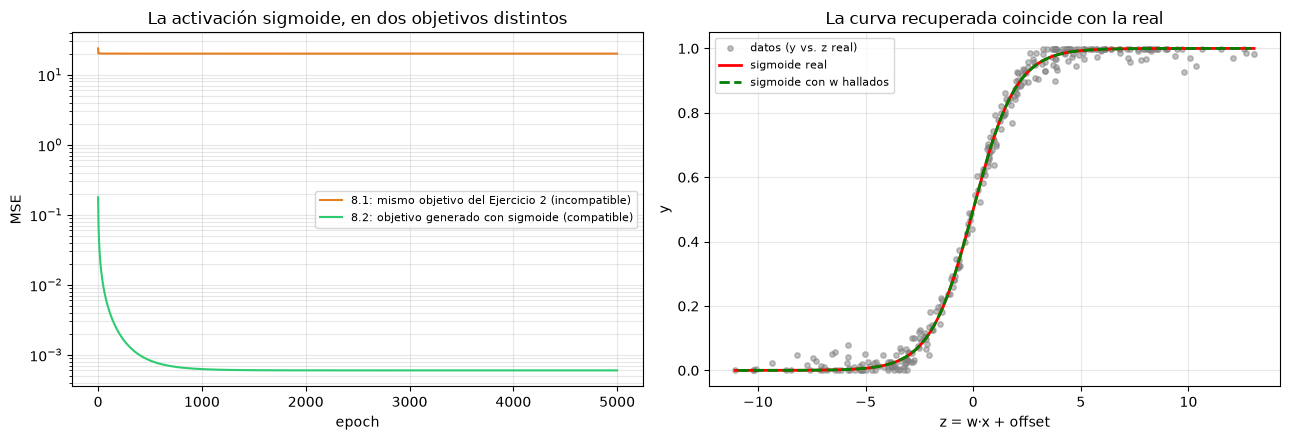

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(hist_sig_a, label="8.1: mismo objetivo del Ejercicio 2 (incompatible)",
             color="#e67e22")
axes[0].plot(hist_sig_b, label="8.2: objetivo generado con sigmoide (compatible)",
             color="#2ecc71")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("MSE")
axes[0].set_yscale("log")
axes[0].set_title("La activación sigmoide, en dos objetivos distintos")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3, which="both")

orden = np.argsort(z_real)
axes[1].scatter(z_real[orden], y_generado_sigmoide[orden], s=15, alpha=0.5,
                label="datos (y vs. z real)", color="gray")
z_linea = np.linspace(z_real.min(), z_real.max(), 200)
axes[1].plot(z_linea, sigmoide(z_linea), color="red", linewidth=2,
             label="sigmoide real")
z_hat = X @ w_sig_b + offset_sig_b
orden_hat = np.argsort(z_hat)
axes[1].plot(z_hat[orden_hat], sigmoide(z_hat[orden_hat]), color="green",
             linewidth=2, linestyle="--", label="sigmoide con w hallados")
axes[1].set_xlabel("z = w·x + offset"); axes[1].set_ylabel("y")
axes[1].set_title("La curva recuperada coincide con la real")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

La curva verde punteada (con los pesos que encontró el entrenamiento) queda prácticamente encima de la roja (la sigmoide real), confirmando visualmente que el ajuste no es casualidad: el modelo recuperó la relación subyacente correcta, no solo un buen valor de MSE por azar.

### 8.3 Los mejores $w_i$ encontrados

Con `lr=2.0` y 5000 épocas, el resultado verificado es
$w \approx (1.485,\ -1.971,\ 0.796,\ 2.966,\ -1.179)$ y offset $\approx 0.501$, frente a los reales
$(1.5,\ -2.0,\ 0.8,\ 3.0,\ -1.2)$ y $0.5$, con MSE final $\approx 5.99\times10^{-4}$ y
$\lVert w_{\text{hallado}}-w_{\text{real}}\rVert \approx 0.052$.

In [15]:
print("Resumen de los mejores pesos encontrados:")
for i, w_i in enumerate(w_sig_b, start=1):
    print(f"  w{i} = {w_i:+.4f}   (real: {w_real[i-1]:+.4f})")
print(f"  offset = {offset_sig_b:+.4f}   (real: {b_real:+.4f})")
print()
print(f"MSE final: {hist_sig_b[-1]:.6f}")

Resumen de los mejores pesos encontrados:
  w1 = +1.4850   (real: +1.5000)
  w2 = -1.9709   (real: -2.0000)
  w3 = +0.7956   (real: +0.8000)
  w4 = +2.9664   (real: +3.0000)
  w5 = -1.1790   (real: -1.2000)
  offset = +0.5008   (real: +0.5000)

MSE final: 0.000599


---

## 9. Conclusión de la segunda iteración

**Cambiar solo la activación no basta.** La Sección 8.1 lo deja claro con números: sobre el mismo objetivo amplio del Ejercicio 2, la sigmoide apenas mejora sobre el escalón (MSE 19.98 contra 20.02), porque termina saturada en el 84% de los casos. Una activación diferenciable no sirve de nada si sus pesos se ven forzados a operar en la zona donde su derivada se anula igual, por saturación en vez de por diseño. Es la versión continua del mismo problema del Ejercicio 2: **el rango de salida de la activación tiene que ser compatible con el rango del objetivo.**

**Cuando el objetivo sí es compatible, el resultado es completamente distinto.** Generando $y$ como una sigmoide real de la misma recta $w_{\text{real}}\cdot x+b_{\text{real}}$, el MSE cae a $5.99\times10^{-4}$ (más de 3 órdenes de magnitud mejor que cualquier intento del Ejercicio 2), y los pesos hallados quedan a una distancia de apenas $0.052$ de los reales en norma. **Esta vez la neurona sí aprendió.**

La moraleja completa de los dos ejercicios juntos: para que una neurona entrenada por gradiente funcione hacen falta **dos condiciones a la vez**, no una sola: (1) una activación diferenciable en todo su dominio, y (2) que esa activación pueda efectivamente producir los valores que el objetivo necesita. El escalón fallaba por (1). La sigmoide sobre un objetivo sin acotar fallaba por (2), a pesar de cumplir (1). Solo cuando las dos se cumplen a la vez, como en la Sección 8.2, el entrenamiento iterativo encuentra los pesos correctos.